# 03 · Event effect

**Question:** do major events in Toronto change TTC bus service disruptions, and for which events, hours, routes and causes?

Input: `data/processed/*.csv` (from `01_data_prep`). Findings from `02_eda` shape the design (see its Step 8):
compare each **event hour** with hours of the **same day of the week and hour of the day** outside any event window, holding weather, season and holidays equal.

**Design choices**
- **"The same kind of hour" = day of week × hour (98 groups)**, for example "Friday 8 pm" (7 days × the 14 hours kept). An earlier version used weekday/weekend × hour (28 groups). Toronto FC plays almost only on weekends, and Saturday and Sunday are not alike, so day of week × hour is the fairer comparison. Step 3.4 shows both.
- **Days of events with no start time** (CNE, TIFF, the marathon: 60 days) have no hourly window. They get their own control variable instead of sitting unnoticed in the "no event" group.
- Robustness checks (other event windows, other model choices, dropping hours, fake events) are in `04_verification`. This notebook keeps the main models and the near-venue test.

| Step | Content |
|---|---|
| 1 | The modelling table: one row per hour, with outcomes, event flags and controls |
| 2 | A simple matched comparison: event hours vs the usual for the same day of week and hour |
| 3 | The main regression, with weather, month, holiday and untimed-event-day controls |
| 4 | The near-venue test: is the event effect larger on routes near the venue? |
| 5 | Diversions, long delays and delay minutes |
| 6 | Cause groups |
| 7 | Conclusions: the answer to each research question |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Works whether the kernel starts in notebooks/ or in the project root
PROCESSED = next(p for p in (Path("../data/processed"), Path("data/processed")) if p.exists())

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
CODING_CHANGE = pd.Timestamp("2026-04-01")   # new cause-code scheme (see 02_eda, Step 4)
LONG_DELAY_MIN = 30                          # "long delay" = more than 30 minutes
HEAVY_RAIN_MM = 10
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"


## Step 1. The modelling table

One row = one hour, from 11:00 to 1 am (where 99% of event-window hours lie). The table starts from `hourly` and adds, in order:
the **event window of each sport** (1.2; events with no start time have no window), the **outcomes** (1.3), the **controls** (1.4: weekday, hour, month, holiday, weather, coding period, and a flag for days of events with no start time), and the **checks** (1.5).

In [2]:
hourly = pd.read_csv(PROCESSED / "hourly.csv", parse_dates=["datetime", "date"])
events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["date", "start", "end", "window_start", "window_end"])
daily = pd.read_csv(PROCESSED / "daily.csv", parse_dates=["date"])
incidents = pd.read_csv(
    PROCESSED / "incidents.csv", parse_dates=["datetime"],
    usecols=["datetime", "code", "min_delay", "delay_capped", "near_venue", "route"],
)
print(f"hourly: {len(hourly):,} rows | events: {events['event_id'].nunique()} events | incidents: {len(incidents):,}")

hourly: 15,312 rows | events: 358 events | incidents: 107,049


In [3]:
GROUP_OF_TYPE = {"mlb": "mlb", "nhl": "nhl", "nba": "nba", "mls": "mls",
                 "world_cup": "other", "parade": "other", "festival": "other", "road_race": "other"}

timed = events.dropna(subset=["window_start"]).drop_duplicates("event_id")
window_rows = pd.DataFrame(
    [(row.event_id, GROUP_OF_TYPE[row.event_type], hour) for row in timed.itertuples()
     for hour in pd.date_range(row.window_start.floor("h"), row.window_end, freq="h", inclusive="left")],
    columns=["event_id", "group", "datetime"],
)
sport_flags = (
    pd.crosstab(window_rows["datetime"], window_rows["group"]).gt(0)
    .add_prefix("win_").rename_axis(columns=None)
    .reindex(columns=["win_mlb", "win_nhl", "win_nba", "win_mls", "win_other"], fill_value=False)
)

# The rebuilt windows must match the flag from notebook 01 exactly
rebuilt_any = hourly["datetime"].isin(window_rows["datetime"])
assert (rebuilt_any == hourly["in_event_window"]).all(), "rebuilt windows differ from hourly.in_event_window"
print(f"{len(window_rows):,} event-hours rebuilt, {window_rows['datetime'].nunique():,} distinct hours = hourly.in_event_window.sum() = {hourly['in_event_window'].sum():,}")
sport_flags.sum().to_frame("hours inside a window")

2,756 event-hours rebuilt, 2,546 distinct hours = hourly.in_event_window.sum() = 2,546


,hours inside a window
win_mlb,1372
win_nhl,506
win_nba,527
win_mls,239
win_other,112


In [4]:
inc = incidents.assign(
    hour_start=incidents["datetime"].dt.floor("h"),
    is_long=incidents["min_delay"] > LONG_DELAY_MIN,
    is_near=incidents["near_venue"].eq(True),
    is_other_route=incidents["near_venue"].eq(False),
)
extra = inc.groupby("hour_start").agg(
    n_long_delays=("is_long", "sum"), n_near_venue=("is_near", "sum"), n_other_routes=("is_other_route", "sum"),
).rename_axis("datetime").reset_index()

outcomes = hourly[["datetime", "n_incidents", "n_diversion", "delay_min_total", "n_delays"]].merge(
    extra, on="datetime", how="left", validate="one_to_one"
).fillna(0)
for col in ["n_long_delays", "n_near_venue", "n_other_routes"]:
    outcomes[col] = outcomes[col].astype(int)
outcomes = outcomes.rename(columns={"delay_min_total": "delay_minutes"})

# Totals must agree with the incident file
assert outcomes["n_incidents"].sum() == len(incidents)
assert outcomes["n_long_delays"].sum() == (incidents["min_delay"] > LONG_DELAY_MIN).sum()
assert outcomes["n_near_venue"].sum() + outcomes["n_other_routes"].sum() == incidents["near_venue"].notna().sum()
outcomes.describe().loc[["mean", "50%", "max"]].round(2)

,datetime,n_incidents,n_diversion,delay_minutes,n_delays,n_long_delays,n_near_venue,n_other_routes
mean,2025-11-15 23:30:00,6.99,0.51,137.42,6.09,0.47,0.61,6.12
50%,2025-11-15 23:30:00,6.00,0.00,94.00,5.00,0.00,0.00,5.00
max,2026-09-30 23:00:00,68.00,17.00,3710.00,66.00,13.00,15.00,63.00


In [5]:
day_controls = daily[["date", "is_holiday", "temp_mean_c", "rain_mm", "snow_cm", "snow_3d_cm", "n_events"]].copy()
day_controls["multi_event_day"] = day_controls["n_events"] >= 2
day_controls["is_holiday"] = day_controls["is_holiday"].astype(bool)
# Events with no start time (CNE, TIFF, the marathon) have no hourly window. Without a flag their days would
# count as "no event" and sit in the comparison group, so they get their own control variable.
untimed_days = set(events.loc[events["window_start"].isna(), "date"])
day_controls["untimed_event_day"] = day_controls["date"].isin(untimed_days)
day_controls["heavy_rain"] = day_controls["rain_mm"] >= HEAVY_RAIN_MM
day_controls["temp_band"] = pd.cut(day_controls["temp_mean_c"], [-40, -10, 0, 10, 20, 25, 40],
                                   labels=["below -10", "-10 to 0", "0 to 10", "10 to 20", "20 to 25", "above 25"])

controls = hourly[["datetime", "date", "hour", "weekday", "is_weekend", "month", "year"]].merge(
    day_controls.drop(columns="n_events"), on="date", how="left", validate="many_to_one"
)
controls["weekday_type"] = np.where(controls["is_weekend"], "weekend", "weekday")
controls["period"] = controls["date"].dt.to_period("M").astype(str)       # year-month
controls["after_coding_change"] = controls["date"] >= CODING_CHANGE
controls["slot"] = controls["weekday_type"] + "_" + controls["hour"].astype(str)           # 48 groups
controls["weekday_slot"] = controls["weekday"] + "_" + controls["hour"].astype(str)        # 168 groups
controls.drop(columns=["is_weekend"]).head(3)

,datetime,date,hour,weekday,month,year,is_holiday,temp_mean_c,rain_mm,snow_cm,snow_3d_cm,multi_event_day,untimed_event_day,heavy_rain,temp_band,weekday_type,period,after_coding_change,slot,weekday_slot
0,2025-01-01 00:00:00,2025-01-01,0,Wednesday,1,2025,True,1.3,0.7,0.0,0.0,False,False,False,0 to 10,weekday,2025-01,False,weekday_0,Wednesday_0
1,2025-01-01 01:00:00,2025-01-01,1,Wednesday,1,2025,True,1.3,0.7,0.0,0.0,False,False,False,0 to 10,weekday,2025-01,False,weekday_1,Wednesday_1
2,2025-01-01 02:00:00,2025-01-01,2,Wednesday,1,2025,True,1.3,0.7,0.0,0.0,False,False,False,0 to 10,weekday,2025-01,False,weekday_2,Wednesday_2


In [6]:
model_hours = (
    outcomes.merge(controls, on="datetime", how="left", validate="one_to_one")
    .merge(hourly[["datetime", "in_event_window", "n_events_active"]], on="datetime", how="left", validate="one_to_one")
    .merge(sport_flags.reset_index(), on="datetime", how="left", validate="one_to_one")
)
flag_cols = ["win_mlb", "win_nhl", "win_nba", "win_mls", "win_other"]
model_hours[flag_cols] = model_hours[flag_cols].fillna(False).astype(bool)

in_scope = (model_hours["hour"] >= 11) | (model_hours["hour"] == 0)
dropped_windows = model_hours.loc[~in_scope, "in_event_window"].sum()
model_hours = model_hours[in_scope].reset_index(drop=True)

print(f"{len(model_hours):,} hours kept of {len(hourly):,} | event-window hours kept: {model_hours['in_event_window'].sum():,} "
      f"({model_hours['in_event_window'].sum() / hourly['in_event_window'].sum():.1%}) | window hours dropped: {dropped_windows}")
model_hours.head(3).T

# Hourly counts by cause group (used in Step 6)
causes = pd.read_csv(PROCESSED / "incidents.csv", parse_dates=["datetime"], usecols=["datetime", "cause_group"])
cause_hourly = (pd.crosstab(causes["datetime"].dt.floor("h"), causes["cause_group"])
                .reindex(columns=["Equipment", "Miscellaneous", "Operator", "Security"], fill_value=0)
                .add_prefix("n_cause_").rename_axis(index="datetime", columns=None).reset_index())
model_hours = model_hours.merge(cause_hourly, on="datetime", how="left", validate="one_to_one")
cause_cols = [c for c in model_hours.columns if c.startswith("n_cause_")]
model_hours[cause_cols] = model_hours[cause_cols].fillna(0).astype(int)


# ---- checks
# 1. no missing values in the columns the models will use
model_columns = ["n_incidents", "n_diversion", "delay_minutes", "n_long_delays", "in_event_window", "slot", "weekday_slot", "month", "period",
                 "is_holiday", "temp_band", "snow_cm", "snow_3d_cm", "heavy_rain", "after_coding_change", "multi_event_day", "untimed_event_day"]
assert model_hours[model_columns].notna().all().all(), "missing values in model columns"

# 2. one row per hour, in order
assert model_hours["datetime"].is_unique and model_hours["datetime"].is_monotonic_increasing

# 3. sport flags agree with the any-window flag
assert (model_hours[flag_cols].any(axis=1) == model_hours["in_event_window"]).all()

# 4. several sports inside the same hour are counted in each flag
overlap_hours = (model_hours[flag_cols].sum(axis=1) > 1).sum()
print(f"All checks passed | hours inside windows of more than one group: {overlap_hours}")

8,932 hours kept of 15,312 | event-window hours kept: 2,519 (98.9%) | window hours dropped: 27


All checks passed | hours inside windows of more than one group: 198


In [7]:
balance = model_hours.groupby("in_event_window").agg(
    hours=("datetime", "size"),
    pct_weekend=("weekday_type", lambda s: (s == "weekend").mean() * 100),
    pct_holiday=("is_holiday", lambda s: s.mean() * 100),
    mean_temp_c=("temp_mean_c", "mean"),
    pct_snow_day=("snow_cm", lambda s: (s > 0).mean() * 100),
    pct_snow_3d_over_5cm=("snow_3d_cm", lambda s: (s > 5).mean() * 100),
    pct_heavy_rain=("heavy_rain", lambda s: s.mean() * 100),
    pct_after_coding_change=("after_coding_change", lambda s: s.mean() * 100),
    pct_multi_event_day=("multi_event_day", lambda s: s.mean() * 100),
    pct_untimed_event_day=("untimed_event_day", lambda s: s.mean() * 100),
).rename(index={False: "no window", True: "inside a window"})
balance.round(1).T

in_event_window,no window,inside a window
hours,6413.0,2519.0
pct_weekend,25.4,36.4
pct_holiday,2.4,2.1
mean_temp_c,9.7,10.0
pct_snow_day,15.4,10.8
pct_snow_3d_over_5cm,8.6,5.4
pct_heavy_rain,6.2,6.9
pct_after_coding_change,28.2,30.0
pct_multi_event_day,4.6,25.0
pct_untimed_event_day,9.2,10.0


**What the table shows**
- **8,932 hours** (638 days) with **2,519 of the 2,546 event-window hours (98.9%)**. Window hours by group: baseball 1,366, basketball 525, hockey 506, Toronto FC 239, other city events 93. 198 hours are inside the windows of more than one group (they count in each).
- About **7 incidents an hour** over the whole period; routes near a venue have only **0.61** an hour (other routes 6.12), so near-venue results need many pooled windows.
- All checks pass: no missing values, one row per hour, sport flags agree with the any-window flag.

**Event hours are not a random sample (the balance table).** Compared with other hours they are more often on weekends (36% vs 25%), less often on snow days (10.8% vs 15.4%), and 25% of them are on days with two or more events (vs 4.6%). The days of events with no start time are 10.0% of event hours and 9.2% of other hours, so they are spread about evenly. The model has to control for all of these.

## Step 2. A simple matched comparison

**Idea.** For every day-of-week × hour slot (for example "Wednesday 8 pm", 98 slots) we know the usual number of incidents on hours **outside any event window**. For each event hour that usual number is the *expected* count. **Ratio = observed ÷ expected** over a group of event hours: 1.00 = as usual, 1.10 = 10% more, 0.90 = 10% fewer.

**Uncertainty.** The 95% interval comes from resampling **whole evenings** (1,000 times), because hours on the same evening move together.

This controls day of week and hour only. Weather, month and holidays come in with the regression in Step 3.

In [8]:
GROUPS = {"Baseball": "win_mlb", "Hockey": "win_nhl", "Basketball": "win_nba",
          "Toronto FC": "win_mls", "Other events": "win_other", "Any event": "in_event_window"}
GROUP_COLORS = {"Baseball": "#2e86c1", "Hockey": "#1f3a5f", "Basketball": "#c0392b",
                "Toronto FC": "#6aa84f", "Other events": "#8e7cc3", "Any event": "black"}
SLOT168 = ["weekday_slot"]
N_BOOT = 1000
RNG = np.random.default_rng(42)

# an evening belongs to the day it started: the hour after midnight goes with the previous evening
model_hours["evening_date"] = (model_hours["datetime"] - pd.Timedelta(hours=6)).dt.normalize()
model_hours["snowy"] = model_hours["snow_3d_cm"] > 2



def add_expected(df, keys, outcome, baseline=None):
    """Add `expected`: mean of `outcome` over hours outside any window, for the same values of `keys`."""
    base_df = df if baseline is None else baseline
    base = base_df.loc[~base_df["in_event_window"]].groupby(keys, observed=True)[outcome].mean().rename("expected")
    return df.join(base, on=keys)


def summarise_ratio(d, outcome, n_boot=N_BOOT):
    """d: rows with the observed `outcome`, `expected` and a `cluster` column. Returns the ratio and a bootstrap interval."""
    d = d[d["expected"].notna()]
    if len(d) == 0:
        return dict(hours=0, observed=np.nan, expected=np.nan, ratio=np.nan, lo=np.nan, hi=np.nan)
    per = d.groupby("cluster")[[outcome, "expected"]].sum()
    obs, exp = per[outcome].to_numpy(), per["expected"].to_numpy()
    draws = RNG.integers(0, len(per), (n_boot, len(per)))
    boot = obs[draws].sum(axis=1) / exp[draws].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return dict(hours=len(d), observed=d[outcome].mean(), expected=d["expected"].mean(), ratio=obs.sum() / exp.sum(), lo=lo, hi=hi)


def ratio_table(df, outcome, keys=SLOT168, groups=GROUPS, baseline=None):
    d = add_expected(df, keys, outcome, baseline).assign(cluster=lambda t: t["evening_date"])
    return pd.DataFrame({name: summarise_ratio(d[d[flag]], outcome) for name, flag in groups.items()}).T


def forest(ax, table, title, show_hours=True):
    """One dot per group with its interval; the red line is 'same as usual'."""
    y = np.arange(len(table))[::-1]
    for yi, (name, row) in zip(y, table.iterrows()):
        ax.errorbar(row["ratio"], yi, xerr=[[row["ratio"] - row["lo"]], [row["hi"] - row["ratio"]]], fmt="o",
                    color=GROUP_COLORS.get(name, "steelblue"), capsize=3)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{n} (n={int(h):,})" if show_hours else n for n, h in zip(table.index, table["hours"])])
    ax.set(title=title, xlabel="ratio (1.0 = same as usual)")


def fmt(table):
    """Readable table: ratio with its interval."""
    return pd.DataFrame({"hours": table["hours"].astype(int), "observed": table["observed"].round(2), "expected": table["expected"].round(2),
                         "ratio": table["ratio"].round(3), "95% interval": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(table["lo"], table["hi"])]})

,hours,observed,expected,ratio,95% interval
Baseball,1366,7.79,7.85,0.992,0.95 to 1.04
Hockey,506,7.14,7.44,0.959,0.88 to 1.05
Basketball,525,6.44,7.09,0.909,0.84 to 0.98
Toronto FC,239,7.91,8.22,0.963,0.89 to 1.03
Other events,93,8.03,8.47,0.948,0.86 to 1.03
Any event,2519,7.38,7.61,0.970,0.94 to 1.00


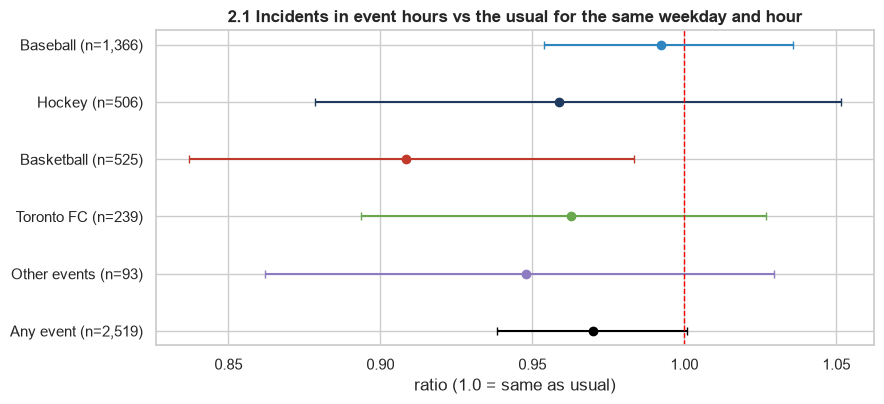

In [9]:
main_incidents = ratio_table(model_hours, "n_incidents")
fig, ax = plt.subplots(figsize=(9, 4.2))
forest(ax, main_incidents, "2.1 Incidents in event hours vs the usual for the same weekday and hour")
plt.tight_layout()
fmt(main_incidents)

**What it shows:** no group is clearly above 1. Baseball 0.99, hockey 0.96, Toronto FC 0.96, other events 0.95 and any event 0.97 (0.94 to 1.00) all include or touch 1.0. **Basketball is the one group clearly below 1: 0.91 (0.84 to 0.98).**
The next step adds weather, month and holidays.

## Step 3. The main regression

**The idea.** Given the day of week, hour, month, weather and holiday, how many incidents would we normally expect in an hour? Is an event hour higher or lower than that?

> incidents in an hour = a **usual level** for that kind of hour × a **weather and calendar adjustment** × an **event adjustment** (one per type of event)

| Piece | In plain words | Entered as |
|---|---|---|
| Event | Is the hour inside a baseball, hockey, basketball, Toronto FC or other-event window? | 5 yes/no flags |
| Kind of hour | Day of week and hour of the day | **98 groups** |
| Month | Some months are busier | 12 months |
| Holiday | Public holidays are quiet | yes/no |
| Snow | Snow that day, and more than 5 cm in the last 3 days | 2 yes/no flags |
| Temperature | Very cold or very hot days differ | 6 bands (10 to 20 C is the reference) |
| Heavy rain | 10 mm or more that day | yes/no |
| After April 2026 | The cause codes changed on 2026-04-01 | yes/no |
| Several events that day | Keeps double-event days from distorting the single-event ones | yes/no |
| **CNE / TIFF / marathon day** | Events with no start time have no window; their days must not count as "no event" | yes/no |

Every piece comes out as a **rate ratio** (1.00 = no difference, 0.90 = 10% fewer). It is a Poisson regression, which fits small whole numbers; uncertainty is computed by evening (cluster-robust), because the data vary about twice as much as a plain Poisson assumes (2.00×).

In [10]:
model_data = model_hours.copy()
model_data["snow_day"] = (model_data["snow_cm"] > 0).astype(int)
model_data["snow3_over5"] = (model_data["snow_3d_cm"] > 5).astype(int)
for col in ["win_mlb", "win_nhl", "win_nba", "win_mls", "win_other", "is_holiday", "heavy_rain", "after_coding_change", "multi_event_day", "untimed_event_day"]:
    model_data[col] = model_data[col].astype(int)
model_data["temp_band"] = model_data["temp_band"].astype(str)

EVENT_FLAGS = {"win_mlb": "Baseball", "win_nhl": "Hockey", "win_nba": "Basketball", "win_mls": "Toronto FC", "win_other": "Other events"}
EVENTS_RHS = " + ".join(EVENT_FLAGS)
CTRL = "C(month) + is_holiday + snow_day + snow3_over5 + C(temp_band, Treatment('10 to 20')) + heavy_rain + after_coding_change + multi_event_day"
SPECS = {
    "A. earlier version: 28 groups (weekday/weekend x hour)": f"C(slot) + {CTRL}",
    "B. 98 groups (day of week x hour)": f"C(weekday_slot) + {CTRL}",
    "C. B + untimed event days (MAIN)": f"C(weekday_slot) + {CTRL} + untimed_event_day",
}
main_rhs = SPECS["C. B + untimed event days (MAIN)"]


def fit_poisson(df, outcome, rhs):
    """Poisson regression with standard errors clustered by evening."""
    model = smf.glm(f"{outcome} ~ {EVENTS_RHS} + {rhs}", data=df, family=sm.families.Poisson())
    return model.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(df["evening_date"])[0]})


def rate_ratios(result):
    ci = result.conf_int()
    return pd.DataFrame({"rate_ratio": np.exp(result.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p_value": result.pvalues})


main = fit_poisson(model_data, "n_incidents", main_rhs)
print(f"{int(main.nobs):,} hours | {model_data['evening_date'].nunique()} evenings (clusters) | converged: {main.converged} | "
      f"spread of the data vs plain Poisson: {main.pearson_chi2 / main.df_resid:.2f}x")

8,932 hours | 639 evenings (clusters) | converged: True | spread of the data vs plain Poisson: 2.00x


,hours,rate_ratio,95% interval,p_value
Baseball,1366,1.030,0.98 to 1.08,0.217
Hockey,506,0.970,0.89 to 1.06,0.490
Basketball,525,0.930,0.86 to 1.01,0.074
Toronto FC,239,0.985,0.90 to 1.07,0.731
Other events,93,0.944,0.84 to 1.06,0.313


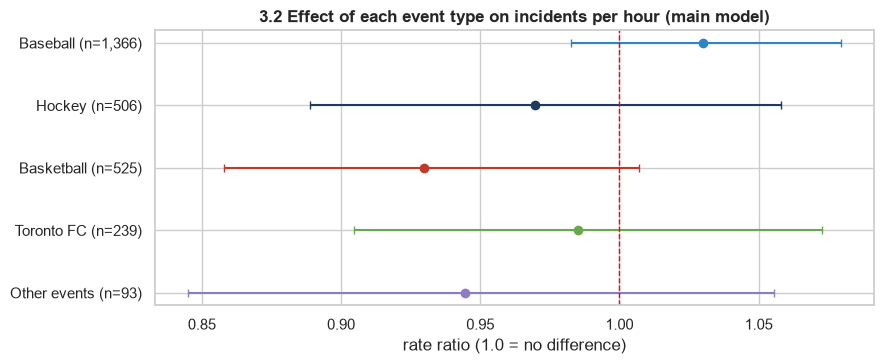

In [11]:
rr = rate_ratios(main)
events_rr = rr.loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)
events_rr["hours"] = [int(model_data[f].sum()) for f in EVENT_FLAGS]

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(events_rr))[::-1]
for yi, (name, row) in zip(y, events_rr.iterrows()):
    ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[name], capsize=3)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_yticks(y)
ax.set_yticklabels([f"{n} (n={h:,})" for n, h in zip(events_rr.index, events_rr["hours"])])
ax.set(title="3.2 Effect of each event type on incidents per hour (main model)", xlabel="rate ratio (1.0 = no difference)")
plt.tight_layout()
events_rr.assign(**{"95% interval": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(events_rr["lo"], events_rr["hi"])]})[["hours", "rate_ratio", "95% interval", "p_value"]].round(3)

In [12]:
no_event = model_data.copy()
no_event[list(EVENT_FLAGS)] = 0
model_data["fitted"] = main.predict(model_data)
model_data["expected_no_event"] = main.predict(no_event)

rows = {}
for flag, name in EVENT_FLAGS.items():
    sel = model_data[flag] == 1
    rows[name] = {"event hours": int(sel.sum()), "expected without event": model_data.loc[sel, "expected_no_event"].mean(),
                  "actual": model_data.loc[sel, "n_incidents"].mean()}
table = pd.DataFrame(rows).T
table["difference per hour"] = table["actual"] - table["expected without event"]
table["difference per event (about 8 hours)"] = table["difference per hour"] * 8

table.round(2)

,event hours,expected without event,actual,difference per hour,difference per event (about 8 hours)
Baseball,1366.0,7.61,7.79,0.18,1.47
Hockey,506.0,7.34,7.14,-0.20,-1.64
Basketball,525.0,6.91,6.44,-0.47,-3.79
Toronto FC,239.0,7.99,7.91,-0.08,-0.61
Other events,93.0,8.41,8.03,-0.38,-3.00


### 3.4 Does the choice of "kind of hour" and the untimed-event control matter?
Three versions of the model, same everything else: **A** the earlier version (28 groups), **B** 98 groups, **C** 98 groups plus the untimed-event-day control (the main model).

,A. earlier version: 28 groups (weekday/weekend x hour),B. 98 groups (day of week x hour),C. B + untimed event days (MAIN)
Baseball,1.03 (0.98 to 1.08),1.02 (0.98 to 1.07),1.03 (0.98 to 1.08)
Hockey,0.96 (0.89 to 1.05),0.96 (0.88 to 1.05),0.97 (0.89 to 1.06)
Basketball,0.91 (0.84 to 0.99),0.93 (0.86 to 1.00),0.93 (0.86 to 1.01)
Toronto FC,1.09 (1.00 to 1.18),0.98 (0.90 to 1.06),0.99 (0.90 to 1.07)
Other events,0.95 (0.84 to 1.08),0.92 (0.83 to 1.03),0.94 (0.84 to 1.06)


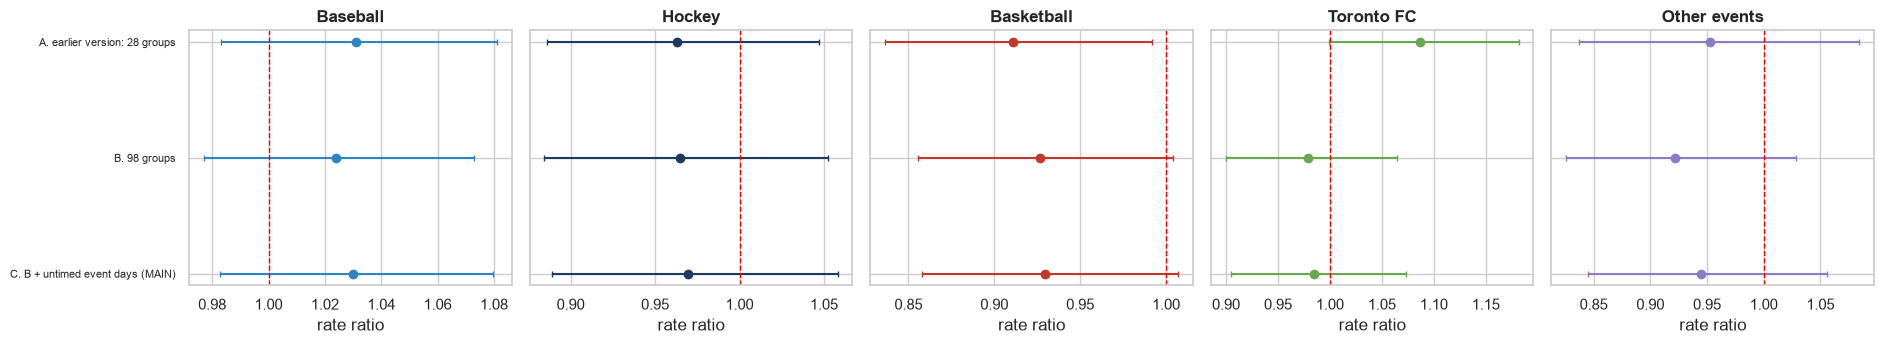

In [13]:
spec_rr = {name: rate_ratios(fit_poisson(model_data, "n_incidents", rhs)).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS) for name, rhs in SPECS.items()}

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6), sharey=True)
labels = list(SPECS)
ypos = np.arange(len(labels))[::-1]
for ax, group in zip(axes, EVENT_FLAGS.values()):
    for yi, name in zip(ypos, labels):
        row = spec_rr[name].loc[group]
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[group], capsize=2)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set(title=group, xlabel="rate ratio")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels([l.split(" (")[0] if "MAIN" not in l else l for l in labels], fontsize=8)
plt.tight_layout()
pd.DataFrame({name: [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(t["rate_ratio"], t["lo"], t["hi"])] for name, t in spec_rr.items()},
             index=list(EVENT_FLAGS.values()))


In [14]:
rr = rate_ratios(main)
control_names = {
    "is_holiday": "Public holiday", "snow_day": "Snow that day", "snow3_over5": "5+ cm snow in last 3 days", "heavy_rain": "Heavy rain (10+ mm)",
    "after_coding_change": "After April 2026 (coding change)", "multi_event_day": "Several events that day", "untimed_event_day": "Day of CNE / TIFF / marathon (no start time)",
    "C(temp_band, Treatment('10 to 20'))[T.below -10]": "Below -10 C (vs 10 to 20 C)",
    "C(temp_band, Treatment('10 to 20'))[T.-10 to 0]": "-10 to 0 C",
    "C(temp_band, Treatment('10 to 20'))[T.0 to 10]": "0 to 10 C",
    "C(temp_band, Treatment('10 to 20'))[T.20 to 25]": "20 to 25 C",
    "C(temp_band, Treatment('10 to 20'))[T.above 25]": "Above 25 C",
}
controls_rr = rr.loc[list(control_names)].rename(index=control_names)
controls_rr.round(3)

,rate_ratio,lo,hi,p_value
Public holiday,0.706,0.624,0.798,0.000
Snow that day,1.160,1.082,1.244,0.000
5+ cm snow in last 3 days,1.204,1.094,1.325,0.000
Heavy rain (10+ mm),1.148,1.077,1.223,0.000
After April 2026 (coding change),0.922,0.887,0.958,0.000
Several events that day,0.975,0.909,1.046,0.476
Day of CNE / TIFF / marathon (no start time),1.077,1.001,1.159,0.048
Below -10 C (vs 10 to 20 C),1.210,1.025,1.428,0.024
-10 to 0 C,0.924,0.841,1.016,0.104
0 to 10 C,0.969,0.911,1.032,0.329


**Main result (model C, incidents per hour).** Baseball 1.03 (0.98 to 1.08), hockey 0.97 (0.89 to 1.06), basketball 0.93 (0.86 to 1.01), Toronto FC 0.99 (0.90 to 1.07), other events 0.94 (0.84 to 1.06). **No event type has an interval that excludes 1.0.**
In incident terms, basketball hours have about 0.5 fewer incidents an hour than the model expects (about 4 fewer over an 8-hour event), not a clear difference.

**What the finer groups change (3.4).**
- **Toronto FC: 1.09 (1.00 to 1.18) with 28 groups, 0.98 to 0.99 with 98.** The earlier rise came from mixing Saturdays and Sundays (Toronto FC plays almost only on weekends). It is not a finding.
- **Basketball: 0.91 (0.84 to 0.99) with 28 groups, 0.93 (0.86 to 1.00 / 1.01) with 98.** It moves from "just clear" to "just not clear" for incidents. (Delay minutes stay clearly lower: Step 5.)
- Baseball, hockey and other events barely move.

**The untimed-event-day control (A→B→C).** Those days run **about 8% higher** than other days (1.08, 1.00 to 1.16, borderline), so leaving them in the comparison group raised the baseline slightly. Adding the control moves the event estimates by at most 0.02.

**Controls (3.5), for scale.** A public holiday is 29% lower (0.71), a snow day 16% higher (1.16), 5+ cm of snow in the last 3 days 20% higher (1.20), heavy rain 15% higher (1.15), a day above 25 C 32% higher (1.32), and after the April 2026 coding change 8% lower (0.92). These are bigger than any event effect here.

## Step 4. The near-venue test

**The question.** Do events add **more** incidents on the routes that run near a venue than on the rest of the network?

**How "near" is defined.** A route is near a venue if **one of its stops is within 1 km** of Rogers Centre, Scotiabank Arena or BMO Field (GTFS stops, straight line): **21 routes** (33 within 3 km). This is a property of the *route*, not of where an incident happened.

**How the data is arranged.** Each hour gets **two rows**: the incidents on the 21 near-venue routes and the incidents on all other routes (17,864 rows).

> incidents on a route group in an hour = a **usual level for that group** (its own pattern by day-of-week × hour and month) × **weather and calendar adjustment** (the same for both groups) × **event effect on other routes** × **extra event effect near the venue**

| Quantity | Meaning |
|---|---|
| **Other routes** | The event effect on the rest of the network (rate ratio). |
| **Extra near-venue effect** | Near-venue ratio ÷ other-routes ratio. **1.00 = same near the venue as elsewhere.** |
| **Near-venue routes** | The event effect on the near-venue routes themselves. |

Events are grouped into two flags (sports, other city events) so the near-venue routes, with only about 0.6 incidents an hour, have enough data. Intervals are computed by evening.

In [15]:
route_dist = pd.read_csv(PROCESSED / "route_venue_dist.csv")

# one row per event-hour with its offset from the start (used for the before/during/after split and the fake events)
timed_info = timed.set_index("event_id")[["start"]]
ev_hours = window_rows.join(timed_info, on="event_id")
ev_hours["offset"] = np.floor((ev_hours["datetime"] - ev_hours["start"].dt.floor("h")) / pd.Timedelta(hours=1)).astype(int)
model_data["win_sports"] = (model_data[["win_mlb", "win_nhl", "win_nba", "win_mls"]].sum(axis=1) > 0).astype(int)
CONTROLS = ("is_holiday + snow_day + snow3_over5 + C(temp_band, Treatment('10 to 20')) + heavy_rain + after_coding_change + multi_event_day + untimed_event_day")


def hourly_count(mask):
    """Incidents per hour for the incidents selected by `mask`, aligned with model_data."""
    counts = incidents.loc[mask].groupby(incidents["datetime"].dt.floor("h")).size()
    return counts.reindex(model_data["datetime"], fill_value=0).to_numpy()


def stack(near_counts, other_counts, data=None):
    """Two rows per hour: near-venue routes and the other routes."""
    data = model_data if data is None else data
    return pd.concat([data.assign(grp="near", count=near_counts, near=1), data.assign(grp="other", count=other_counts, near=0)], ignore_index=True)


def fit_near(st, flags, controls=CONTROLS):
    """Poisson: each group has its own usual level (slot, month); flags and flags x near are the event effects."""
    terms = " + ".join(flags) + " + " + " + ".join(f"{f}:near" for f in flags)
    model = smf.glm(f"count ~ {terms} + C(grp):C(weekday_slot) + C(grp):C(month) + {controls}", data=st, family=sm.families.Poisson())
    return model.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(st["evening_date"])[0]})


def near_effects(res, flags, names=None):
    """For each flag: effect on other routes, extra near-venue effect, and effect on near-venue routes (rate ratios with 95% intervals)."""
    names = names or {f: f for f in flags}
    params, cov = res.params, res.cov_params()
    rows = []
    for f in flags:
        for label, members in [("Other routes", [f]), ("Extra near-venue effect", [f"{f}:near"]), ("Near-venue routes", [f, f"{f}:near"])]:
            L = pd.Series(0.0, index=params.index)
            L[members] = 1.0
            est = float(L @ params)
            se = float(np.sqrt(L @ cov @ L))
            rows.append({"event": names[f], "quantity": label, "rate_ratio": np.exp(est), "lo": np.exp(est - 1.96 * se), "hi": np.exp(est + 1.96 * se)})
    return pd.DataFrame(rows)


near_main = stack(model_data["n_near_venue"].to_numpy(), model_data["n_other_routes"].to_numpy())
print(f"{len(near_main):,} rows | near-venue incidents: {int(model_data['n_near_venue'].sum()):,} "
      f"({int(model_data.loc[model_data['in_event_window'] == 1, 'n_near_venue'].sum()):,} in event hours)")

17,864 rows | near-venue incidents: 5,908 (1,637 in event hours)


### 4.1 The raw numbers first
Near-venue routes have **0.67 incidents an hour with no event, 0.64 in sports hours and 0.91 in city-event hours**; their share of all incidents is 8.4%, 9.1% and 11.7%. No controls yet.

In [16]:
raw = []
for name, mask in [("no event window", model_data["in_event_window"] == 0), ("sports window", model_data["win_sports"] == 1), ("city-event window", model_data["win_other"] == 1)]:
    sub = model_data[mask]
    raw.append({"hours": name, "n hours": len(sub), "near-venue routes": sub["n_near_venue"].mean(), "other routes": sub["n_other_routes"].mean(),
                "share near venue (%)": sub["n_near_venue"].sum() / (sub["n_near_venue"].sum() + sub["n_other_routes"].sum()) * 100})
raw = pd.DataFrame(raw).set_index("hours")
raw.round(2)

,n hours,near-venue routes,other routes,share near venue (%)
hours,,,,
no event window,6413,0.67,7.24,8.43
sports window,2467,0.64,6.43,9.10
city-event window,93,0.91,6.92,11.66


### 4.2 Main result: sports and other city events

quantity,Other routes,Extra near-venue effect,Near-venue routes
event,,,
"Other city events (parades, festivals, World Cup)",0.93 (0.83 to 1.04),1.30 (1.14 to 1.48),1.21 (1.04 to 1.40)
"Sports (baseball, hockey, basketball, Toronto FC)",0.99 (0.94 to 1.03),1.01 (0.94 to 1.09),1.00 (0.92 to 1.08)


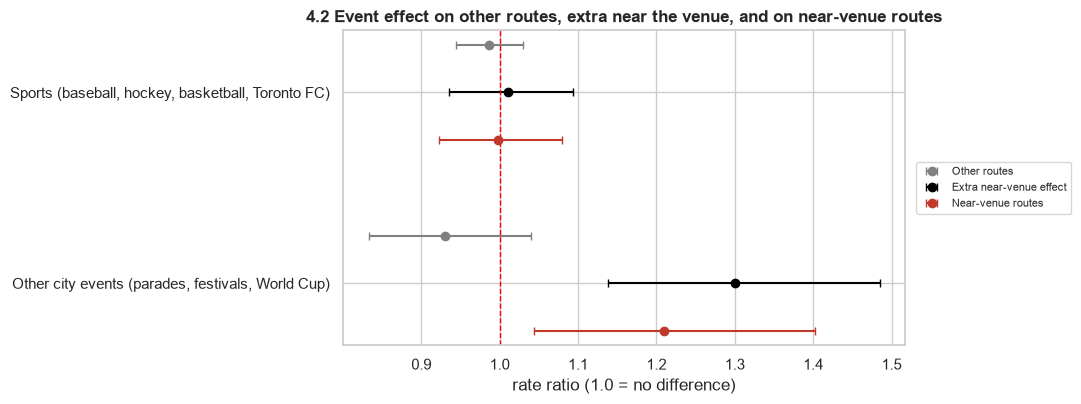

In [17]:
FLAGS_MAIN = ["win_sports", "win_other"]
NAMES_MAIN = {"win_sports": "Sports (baseball, hockey, basketball, Toronto FC)", "win_other": "Other city events (parades, festivals, World Cup)"}
res_main = fit_near(near_main, FLAGS_MAIN)
effects_main = near_effects(res_main, FLAGS_MAIN, NAMES_MAIN)
QUANTITY_COLORS = {"Other routes": "gray", "Extra near-venue effect": "black", "Near-venue routes": "#c0392b"}


def plot_effects(effects, title, figsize=(11, 4.2)):
    events_list = list(dict.fromkeys(effects["event"]))
    fig, ax = plt.subplots(figsize=figsize)
    for i, ev_name in enumerate(events_list[::-1]):
        for j, q in enumerate(QUANTITY_COLORS):
            row = effects[(effects["event"] == ev_name) & (effects["quantity"] == q)].iloc[0]
            y = i + (1 - j) * 0.25
            ax.errorbar(row["rate_ratio"], y, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=QUANTITY_COLORS[q], capsize=3,
                        label=q if i == 0 else None)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(range(len(events_list)))
    ax.set_yticklabels(events_list[::-1])
    ax.set(title=title, xlabel="rate ratio (1.0 = no difference)")
    ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()


def effects_table(effects):
    t = effects.assign(**{"ratio (95% interval)": [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(effects["rate_ratio"], effects["lo"], effects["hi"])]})
    return t.pivot(index="event", columns="quantity", values="ratio (95% interval)")[list(QUANTITY_COLORS)]


plot_effects(effects_main, "4.2 Event effect on other routes, extra near the venue, and on near-venue routes")
effects_table(effects_main)

### 4.3 One effect per event type

quantity,Other routes,Extra near-venue effect,Near-venue routes
event,,,
Baseball,1.02 (0.97 to 1.07),1.03 (0.94 to 1.13),1.05 (0.96 to 1.15)
Basketball,0.93 (0.86 to 1.02),0.96 (0.83 to 1.12),0.90 (0.77 to 1.05)
Hockey,0.97 (0.88 to 1.06),0.98 (0.85 to 1.12),0.95 (0.81 to 1.10)
Other events,0.93 (0.83 to 1.04),1.30 (1.14 to 1.49),1.21 (1.04 to 1.41)
Toronto FC,0.98 (0.89 to 1.07),1.09 (0.89 to 1.32),1.06 (0.88 to 1.28)


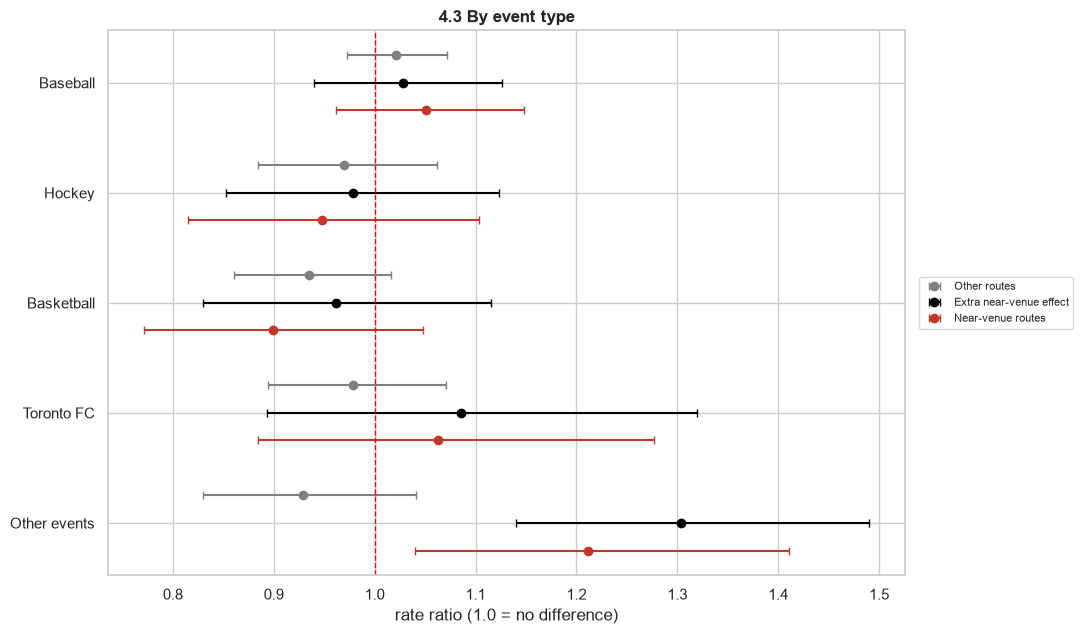

In [18]:
FLAGS_TYPE = list(EVENT_FLAGS)
res_type = fit_near(near_main, FLAGS_TYPE)
effects_type = near_effects(res_type, FLAGS_TYPE, EVENT_FLAGS)
plot_effects(effects_type, "4.3 By event type", figsize=(11, 6.5))
effects_table(effects_type)

### 4.4 Splitting the city events
Parades, the World Cup and festivals together are only 93 hours. Split, each group is tiny, so this shows **where the rise comes from**, not how big each part is.

Event hours in scope: {'win_parade': 43, 'win_world_cup': 42, 'win_festival': 8}


quantity,Other routes,Extra near-venue effect,Near-venue routes,hours
event,,,,
Festivals (Nuit Blanche),1.00 (0.88 to 1.14),1.41 (1.17 to 1.69),1.41 (1.16 to 1.71),8
Parades,0.92 (0.77 to 1.09),1.25 (1.07 to 1.46),1.14 (0.96 to 1.36),43
World Cup,0.93 (0.79 to 1.09),1.35 (1.09 to 1.67),1.25 (0.97 to 1.61),42


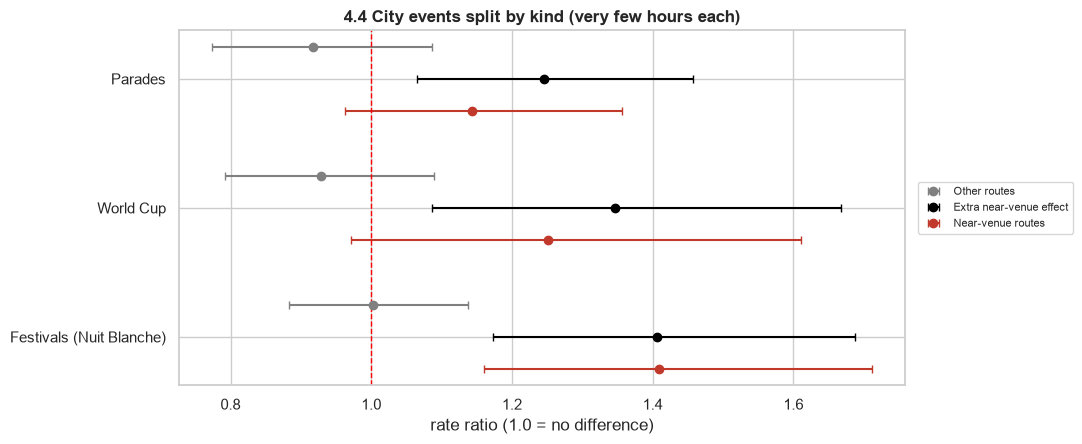

In [19]:
type_of_event = timed.set_index("event_id")["event_type"]
sub_flags = (pd.crosstab(window_rows["datetime"], window_rows["event_id"].map(type_of_event)).gt(0).astype(int)
             .reindex(columns=["parade", "world_cup", "festival"], fill_value=0).add_prefix("win_").reset_index())
split_data = model_data.drop(columns=[c for c in model_data.columns if c in ["win_parade", "win_world_cup", "win_festival"]]).merge(sub_flags, on="datetime", how="left")
for col in ["win_parade", "win_world_cup", "win_festival"]:
    split_data[col] = split_data[col].fillna(0).astype(int)
hours_by_sub = {c: int(split_data[c].sum()) for c in ["win_parade", "win_world_cup", "win_festival"]}
print("Event hours in scope:", hours_by_sub)

near_split = stack(split_data["n_near_venue"].to_numpy(), split_data["n_other_routes"].to_numpy(), data=split_data)
flags_split = ["win_mlb", "win_nhl", "win_nba", "win_mls", "win_parade", "win_world_cup", "win_festival"]
res_split = fit_near(near_split, flags_split)
names_split = {**EVENT_FLAGS, "win_parade": "Parades", "win_world_cup": "World Cup", "win_festival": "Festivals (Nuit Blanche)"}
effects_split = near_effects(res_split, ["win_parade", "win_world_cup", "win_festival"], names_split)
plot_effects(effects_split, "4.4 City events split by kind (very few hours each)", figsize=(11, 4.6))
effects_table(effects_split).assign(hours=[hours_by_sub[k] for k in ["win_festival", "win_parade", "win_world_cup"]])

### 4.5 Before, during and after the start (sports)
Sports hours split into before (2 and 1 hours before), during (first 3 hours) and after (the rest of the window).

quantity,Other routes,Extra near-venue effect,Near-venue routes,hours
event,,,,
Sports: after the end,1.00 (0.94 to 1.08),0.99 (0.86 to 1.13),0.99 (0.86 to 1.13),846
Sports: before the start,0.98 (0.93 to 1.03),1.00 (0.89 to 1.13),0.98 (0.87 to 1.11),660
Sports: during the game,0.98 (0.93 to 1.04),1.03 (0.93 to 1.15),1.02 (0.92 to 1.13),961


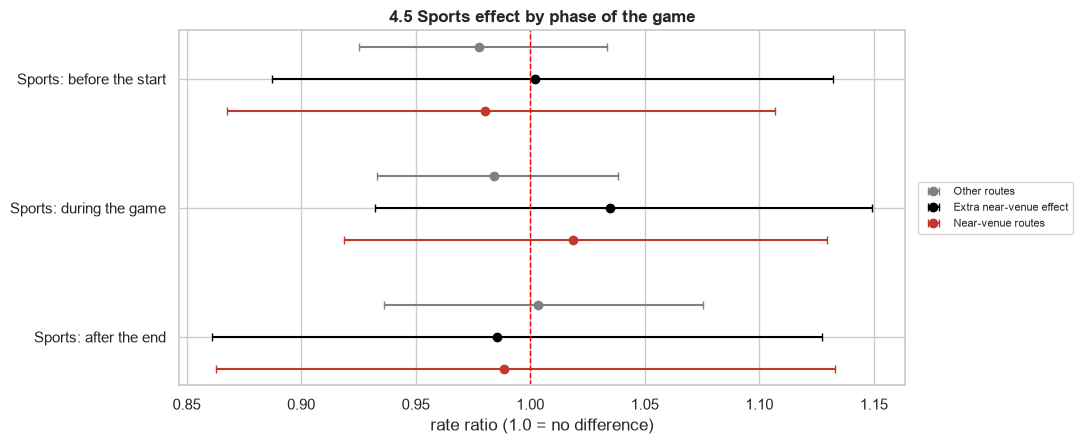

In [20]:
sport_rows = ev_hours[ev_hours["group"].isin(["mlb", "nhl", "nba", "mls"])]
first_offset = sport_rows.groupby("datetime")["offset"].min()
phase = pd.cut(first_offset, [-10, -1, 2, 10], labels=["before", "during", "after"]).rename("phase")
phase_flags = pd.get_dummies(phase).astype(int).add_prefix("win_s_").reset_index()
phase_data = model_data.drop(columns=[c for c in model_data.columns if c.startswith("win_s_")]).merge(phase_flags, on="datetime", how="left")
phase_cols = ["win_s_before", "win_s_during", "win_s_after"]
phase_data[phase_cols] = phase_data[phase_cols].fillna(0).astype(int)
phase_data["win_other_only"] = phase_data["win_other"]
near_phase = stack(phase_data["n_near_venue"].to_numpy(), phase_data["n_other_routes"].to_numpy(), data=phase_data)
res_phase = fit_near(near_phase, phase_cols + ["win_other_only"])
names_phase = {"win_s_before": "Sports: before the start", "win_s_during": "Sports: during the game", "win_s_after": "Sports: after the end"}
effects_phase = near_effects(res_phase, phase_cols, names_phase)
plot_effects(effects_phase, "4.5 Sports effect by phase of the game", figsize=(11, 4.6))
effects_table(effects_phase).assign(hours=[int(phase_data[c].sum()) for c in ["win_s_after", "win_s_before", "win_s_during"]])

### 4.6 Does the definition of "near" change the answer?
**3 km** instead of 1 km, **without night routes (3xx)**, and a **venue-specific** version (a route counts as near only if it is near the venue of that event: baseball at Rogers Centre, hockey and basketball at Scotiabank Arena, Toronto FC at BMO Field).

quantity                                                                     Extra near-venue effect    Near-venue routes
event                                             definition                                                             
Baseball                                          venue-specific                 1.19 (0.95 to 1.48)  1.22 (0.98 to 1.52)
Basketball                                        venue-specific                 1.04 (0.83 to 1.30)  0.96 (0.76 to 1.22)
Hockey                                            venue-specific                 0.94 (0.75 to 1.19)  0.92 (0.74 to 1.13)
Other city events (parades, festivals, World Cup) 1 km, without night routes     1.30 (1.14 to 1.48)  1.21 (1.04 to 1.40)
                                                  3 km                           1.18 (1.03 to 1.35)  1.09 (0.94 to 1.27)
                                                  main: 1 km                     1.30 (1.14 to 1.48)  1.21 (1.04 to 1.40)
Sports (baseball, hockey, basketball, Toronto FC) 1 km, without night routes     1.01 (0.94 to 1.09)  1.00 (0.92 to 1.08)
                                                  3 km                           1.00 (0.93 to 1.07)  0.99 (0.92 to 1.06)
                                                  main: 1 km                     1.01 (0.94 to 1.09)  1.00 (0.92 to 1.08)
Toronto FC                                        venue-specific                 1.26 (1.00 to 1.58)  1.22 (0.97 to 1.54)

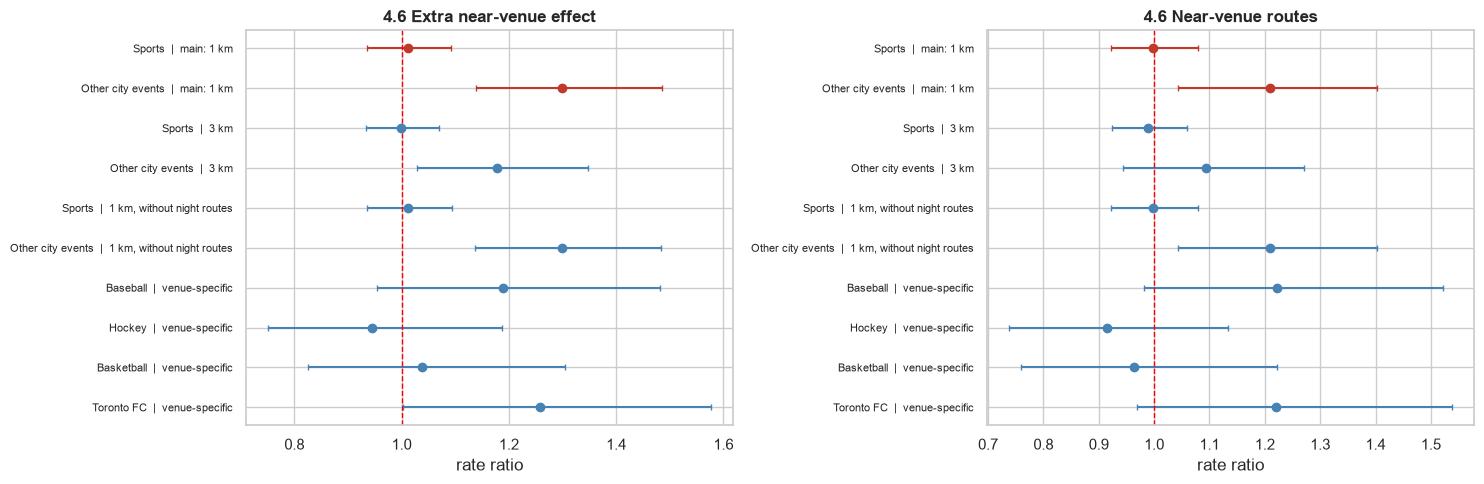

In [21]:
route = incidents["route"]
night = route.between(300, 399)
near1 = incidents["near_venue"].eq(True)
other1 = incidents["near_venue"].eq(False)
near3_routes = set(route_dist.loc[route_dist["dist_venue_km"] <= 3, "route"])
near3 = route.isin(near3_routes)
other3 = route.notna() & ~near3

definitions = {
    "main: 1 km": (hourly_count(near1), hourly_count(other1)),
    "3 km": (hourly_count(near3), hourly_count(other3)),
    "1 km, without night routes": (hourly_count(near1 & ~night), hourly_count(other1 & ~night)),
}
sens_rows = []
for name, (n_counts, o_counts) in definitions.items():
    res = fit_near(stack(n_counts, o_counts), FLAGS_MAIN)
    eff = near_effects(res, FLAGS_MAIN, NAMES_MAIN)
    for _, row in eff[eff["quantity"] != "Other routes"].iterrows():
        sens_rows.append({"definition": name, **row.to_dict()})

# venue-specific: one model per sport, with near = within 1 km of that sport's venue
venue_col = {"win_mlb": "dist_rogers_km", "win_nhl": "dist_scotiabank_km", "win_nba": "dist_scotiabank_km", "win_mls": "dist_bmo_km"}
for flag, col in venue_col.items():
    venue_near = set(route_dist.loc[route_dist[col] <= 1, "route"])
    near_v = route.isin(venue_near)
    other_v = route.notna() & ~near_v
    res = fit_near(stack(hourly_count(near_v), hourly_count(other_v)), list(EVENT_FLAGS))
    eff = near_effects(res, [flag], EVENT_FLAGS)
    for _, row in eff[eff["quantity"] != "Other routes"].iterrows():
        sens_rows.append({"definition": "venue-specific", **row.to_dict()})
sens = pd.DataFrame(sens_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, quantity in zip(axes, ["Extra near-venue effect", "Near-venue routes"]):
    sub = sens[sens["quantity"] == quantity].reset_index(drop=True)
    sub["label"] = sub["event"].str.replace(r" \(.*\)", "", regex=True) + "  |  " + sub["definition"]
    y = np.arange(len(sub))[::-1]
    colors = ["#c0392b" if d == "main: 1 km" else "steelblue" for d in sub["definition"]]
    for yi, (_, row), color in zip(y, sub.iterrows(), colors):
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=color, capsize=2)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["label"], fontsize=8)
    ax.set(title=f"4.6 {quantity}", xlabel="rate ratio")
plt.tight_layout()
sens.assign(**{"ratio (95% interval)": [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(sens["rate_ratio"], sens["lo"], sens["hi"])]}).pivot_table(
    index=["event", "definition"], columns="quantity", values="ratio (95% interval)", aggfunc="first")

### 4.7 What does chance look like? Fake city events
The city-event result rests on 93 hours from 12 events. The 12 events are moved to **random days with the same weekday and no event** (also not on CNE, TIFF or marathon days), the model is refitted, repeated 200 times. This shows how far chance alone can go.

/var/folders/_q/d8x01d9j7z12_lfq_8cn9x600000gn/T/ipykernel_35344/3938305232.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cand = np.full((7, cand_len.max()), np.datetime64("NaT"), dtype="datetime64[ns]")


200 refits in 200 s | fake events: extra near-venue effect mean 1.01, 2.5% to 97.5%: 0.69 to 1.35; share as high as the real one: 0.040
Near-venue routes effect: fake mean 1.00, 2.5% to 97.5%: 0.64 to 1.35; share as high as the real one: 0.095
Spread of the extra effect: model standard error 0.068 vs fake-event spread 0.163 (on the log scale)


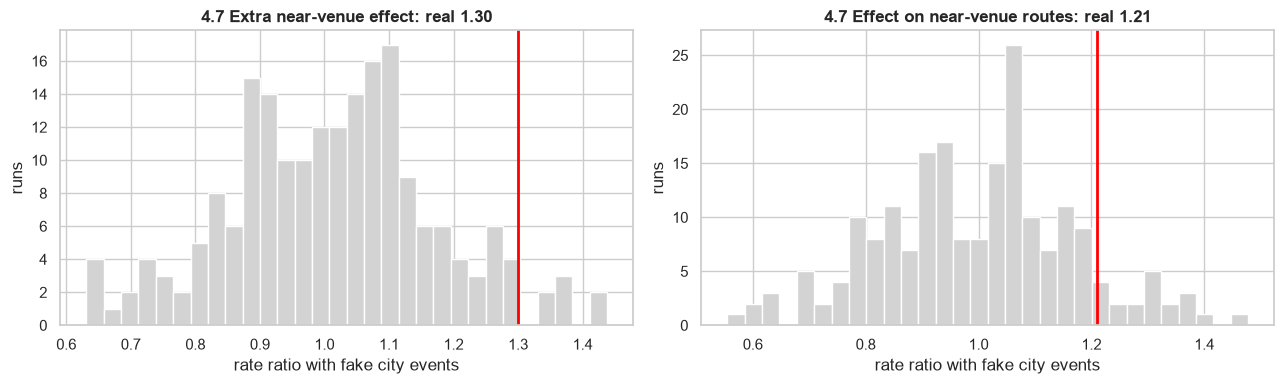

In [22]:
# Candidate days for the fake events: days with no event window and no untimed event (CNE, TIFF, marathon)
event_days = set(model_hours.loc[model_hours["in_event_window"] | (model_hours["untimed_event_day"] == 1), "evening_date"])
free_days = pd.Series(sorted(set(model_hours["evening_date"]) - event_days))
free_by_weekday = [free_days[free_days.dt.day_of_week == k].to_numpy() for k in range(7)]
cand_len = np.array([len(a) for a in free_by_weekday])
cand = np.full((7, cand_len.max()), np.datetime64("NaT"), dtype="datetime64[ns]")
for k, a in enumerate(free_by_weekday):
    cand[k, :len(a)] = a

ev = ev_hours.assign(base_date=lambda t: t["start"].dt.normalize()).merge(model_hours[["datetime"]], on="datetime", how="inner")
ev["offset_h"] = ((ev["datetime"] - ev["base_date"]) / pd.Timedelta(hours=1)).astype(int)
windows = ev.drop_duplicates("event_id")[["event_id", "base_date", "group"]].reset_index(drop=True)
windows["weekday"] = windows["base_date"].dt.day_of_week

import time

other_ev = ev[ev["group"] == "other"].copy()
other_windows = windows[windows["group"] == "other"].reset_index(drop=True)
other_win_index = other_windows.reset_index().set_index("event_id")["index"]
o_win = other_ev["event_id"].map(other_win_index).to_numpy()
o_off = other_ev["offset_h"].to_numpy().astype("timedelta64[h]")
o_wd = other_windows["weekday"].to_numpy()
mh_pos = pd.DatetimeIndex(model_data["datetime"])
real_window = model_data["in_event_window"].to_numpy().astype(bool)


def fake_city_effect(rng):
    pick = (rng.random(len(other_windows)) * cand_len[o_wd]).astype(int)
    target = cand[o_wd, pick][o_win] + o_off
    pos = mh_pos.get_indexer(pd.DatetimeIndex(target))
    pos = pos[(pos >= 0)]
    pos = pos[~real_window[pos]]
    data = model_data.copy()
    data["win_other"] = 0
    data.loc[data.index[pos], "win_other"] = 1
    res = fit_near(stack(data["n_near_venue"].to_numpy(), data["n_other_routes"].to_numpy(), data=data), FLAGS_MAIN)
    eff = near_effects(res, ["win_other"]).set_index("quantity")["rate_ratio"]
    return eff["Extra near-venue effect"], eff["Near-venue routes"]


rng = np.random.default_rng(7)
start = time.time()
fake_runs = np.array([fake_city_effect(rng) for _ in range(200)])
real_extra = effects_main[(effects_main["event"] == NAMES_MAIN["win_other"]) & (effects_main["quantity"] == "Extra near-venue effect")]["rate_ratio"].iloc[0]
real_near = effects_main[(effects_main["event"] == NAMES_MAIN["win_other"]) & (effects_main["quantity"] == "Near-venue routes")]["rate_ratio"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, values, real_value, title in zip(axes, fake_runs.T, [real_extra, real_near], ["Extra near-venue effect", "Effect on near-venue routes"]):
    ax.hist(values, bins=30, color="lightgray")
    ax.axvline(real_value, color="red", lw=2)
    ax.set(title=f"4.7 {title}: real {real_value:.2f}", xlabel="rate ratio with fake city events", ylabel="runs")
plt.tight_layout()
print(f"200 refits in {time.time() - start:.0f} s | fake events: extra near-venue effect mean {fake_runs[:, 0].mean():.2f}, 2.5% to 97.5%: "
      f"{np.percentile(fake_runs[:, 0], 2.5):.2f} to {np.percentile(fake_runs[:, 0], 97.5):.2f}; share as high as the real one: {(fake_runs[:, 0] >= real_extra).mean():.3f}")
print(f"Near-venue routes effect: fake mean {fake_runs[:, 1].mean():.2f}, 2.5% to 97.5%: {np.percentile(fake_runs[:, 1], 2.5):.2f} to {np.percentile(fake_runs[:, 1], 97.5):.2f}; "
      f"share as high as the real one: {(fake_runs[:, 1] >= real_near).mean():.3f}")
model_se = (np.log(effects_main.query("quantity == 'Extra near-venue effect' and event == @NAMES_MAIN['win_other']")["hi"].iloc[0]) - np.log(real_extra)) / 1.96
print(f"Spread of the extra effect: model standard error {model_se:.3f} vs fake-event spread {np.log(fake_runs[:, 0]).std():.3f} (on the log scale)")

**Sports: no near-venue effect under the pooled definition.** Near-venue routes are at 1.00 (0.92 to 1.08) with an extra effect of 1.01 (0.94 to 1.09). Every phase is flat: before 0.98, during 1.02, after 0.99. It holds at 3 km (0.99) and without night routes (1.00). By type, baseball 1.05, hockey 0.95, basketball 0.90 and Toronto FC 1.06 are all within chance. (With 28 groups Toronto FC looked like 1.20; with 98 groups it is gone.)

**But the venue-specific version is not flat.** If "near" means near the venue of that sport, baseball is **1.22 (0.98 to 1.52)** and Toronto FC **1.22 (0.97 to 1.54)** on near-venue routes (extra effect 1.19 and 1.26), hockey 0.92 and basketball 0.96. These are borderline and rest on fewer routes, so they are **leads, not results**; they also mean the pooled "no effect" can hide a small venue-specific effect, because the near group mixes routes from three venues.

**Other city events (parades, World Cup, festivals): a possible rise near the venue.** Near-venue routes **1.21 (1.04 to 1.40)**, and the effect there is **1.30 (1.14 to 1.48)** times the effect elsewhere. World Cup (extra 1.35), parades (1.25) and Nuit Blanche (1.41, 8 hours only) point the same way. It is weaker at 3 km (extra 1.18, near-venue 1.09).

**But the evidence is thin.** It rests on 93 hours from 12 events. With fake events, **4.0%** of fake runs match the extra effect and **9.5%** match the near-venue effect. The model's standard error for the extra effect is 0.068, but the spread across fake events is 0.163, about **2.4 times larger**, so a realistic interval is about **0.95 to 1.8**, not 1.14 to 1.48.

**Size.** A 21% rise on routes that average 0.67 incidents an hour is about 0.14 extra incidents an hour, **about 1 over a whole event window**.

**A limit of the definition.** "Near" is per route. A few long routes dominate the near group (29 Dufferin alone has 2,008 of the 9,399 near-venue incidents; 63, 929, 97 and 75 are also long). These routes run well beyond the neighbourhood of the venue, so many of their incidents probably happen far from it. That would dilute a real effect, so the near-venue estimates are more likely too small than too large. The data cannot confirm this, because the incident location (`Station`) is free text and is not used.

## Step 5. Diversions, long delays and delay minutes

Steps 3 and 4 counted incidents. This step uses the outcomes that say **how disruptive** incidents are: **diversions** (`MFDV`, a bus rerouted; the cause most tied to road closures), **long delays** (more than 30 minutes) and **delay minutes** (capped). Same model as Step 3 (98 groups, same controls). Diversions and long delays are rare (about 0.5 an hour, two thirds of hours have none), so intervals are wider.

{'Diversions per hour': 'mean 0.58 an hour, 65% of hours are zero', 'Long delays (> 30 min) per hour': 'mean 0.53 an hour, 66% of hours are zero', 'Delay minutes per hour (capped)': 'mean 153.23 an hour, 2% of hours are zero'}


,Diversions per hour,Long delays (> 30 min) per hour,Delay minutes per hour (capped)
Baseball,0.97 (0.85 to 1.11),0.89 (0.77 to 1.03),1.00 (0.92 to 1.09)
Hockey,1.10 (0.89 to 1.36),1.00 (0.81 to 1.23),0.98 (0.85 to 1.14)
Basketball,0.88 (0.73 to 1.05),0.85 (0.71 to 1.01),0.85 (0.77 to 0.93)
Toronto FC,0.97 (0.73 to 1.28),0.92 (0.71 to 1.18),0.99 (0.87 to 1.13)
Other events,1.06 (0.71 to 1.59),1.17 (0.84 to 1.63),1.12 (0.93 to 1.34)


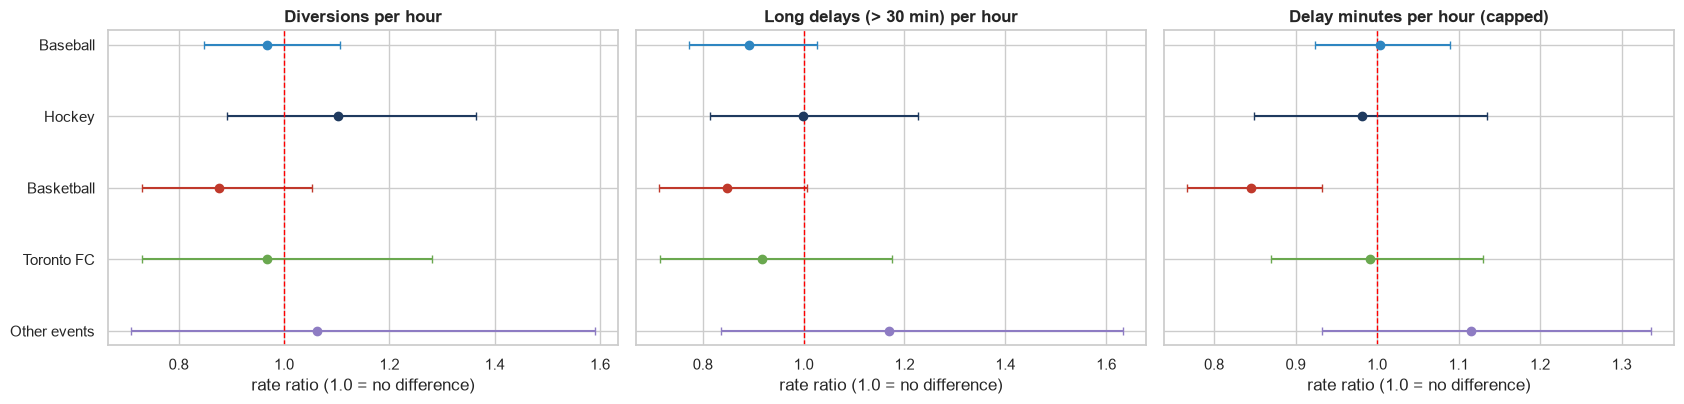

In [23]:
OUTCOME_LABELS = {"n_diversion": "Diversions per hour", "n_long_delays": "Long delays (> 30 min) per hour", "delay_minutes": "Delay minutes per hour (capped)"}
fits = {col: fit_poisson(model_data, col, main_rhs) for col in OUTCOME_LABELS}
outcome_rr = {col: rate_ratios(res).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS) for col, res in fits.items()}
print({OUTCOME_LABELS[c]: f"mean {model_data[c].mean():.2f} an hour, {(model_data[c] == 0).mean():.0%} of hours are zero" for c in OUTCOME_LABELS})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, (col, label) in zip(axes, OUTCOME_LABELS.items()):
    t = outcome_rr[col]
    y = np.arange(len(t))[::-1]
    for yi, (name, row) in zip(y, t.iterrows()):
        ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[name], capsize=3)
    ax.axvline(1, color="red", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index)
    ax.set(title=label, xlabel="rate ratio (1.0 = no difference)")
plt.tight_layout()
pd.DataFrame({OUTCOME_LABELS[c]: [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(t["rate_ratio"], t["lo"], t["hi"])] for c, t in outcome_rr.items()},
             index=list(EVENT_FLAGS.values()))

### 5.2 Does the diversion result hold up?
The diversion model is refitted without the five evenings with the most diversions (2026-09-02 has 55), without snowy days, and without both.

In [24]:
top_days = model_data.groupby("evening_date")["n_diversion"].sum().nlargest(5)
print("Five evenings with the most diversions:", {d.strftime("%Y-%m-%d"): int(n) for d, n in top_days.items()})
CHECKS = {
    "main (all hours)": pd.Series(True, index=model_data.index),
    "without the 5 biggest diversion days": ~model_data["evening_date"].isin(top_days.index),
    "without recent snow (3-day snow <= 2 cm)": ~model_data["snowy"],
    "without both": ~model_data["evening_date"].isin(top_days.index) & ~model_data["snowy"],
}


def rhs_without_constants(data, rhs):
    """Drop yes/no controls that never vary in the subset (they cannot be estimated)."""
    for term in ["snow_day", "snow3_over5", "heavy_rain", "is_holiday", "after_coding_change", "multi_event_day", "untimed_event_day"]:
        if data[term].nunique() < 2:
            rhs = rhs.replace(f" + {term}", "")
    return rhs


check_rr = {}
for name, mask in CHECKS.items():
    subset = model_data[mask]
    result = fit_poisson(subset, "n_diversion", rhs_without_constants(subset, main_rhs))
    check_rr[name] = rate_ratios(result).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)

pd.DataFrame({name: t["rate_ratio"] for name, t in check_rr.items()}).T.round(3)

Five evenings with the most diversions: {'2026-09-02': 55, '2026-01-15': 26, '2025-04-29': 25, '2025-08-31': 24, '2025-10-21': 24}


,Baseball,Hockey,Basketball,Toronto FC,Other events
main (all hours),0.968,1.103,0.877,0.967,1.063
without the 5 biggest diversion days,0.984,1.046,0.897,1.010,1.079
without recent snow (3-day snow <= 2 cm),0.944,1.121,0.817,0.955,1.038
without both,0.960,1.014,0.829,1.004,1.052


### 5.3 Diversions near the venue
The Step 4 model with diversions as the outcome. Only 605 diversions happened on near-venue routes, 178 in event hours and **13 in city-event hours**.

Near-venue diversions: 605 in the period, 178 in event hours, 13 in city-event hours | 94% of hours have none


quantity,Other routes,Extra near-venue effect,Near-venue routes
event,,,
"Other city events (parades, festivals, World Cup)",0.96 (0.60 to 1.53),2.21 (1.16 to 4.21),2.12 (1.23 to 3.65)
"Sports (baseball, hockey, basketball, Toronto FC)",0.95 (0.84 to 1.07),1.09 (0.85 to 1.39),1.03 (0.82 to 1.29)


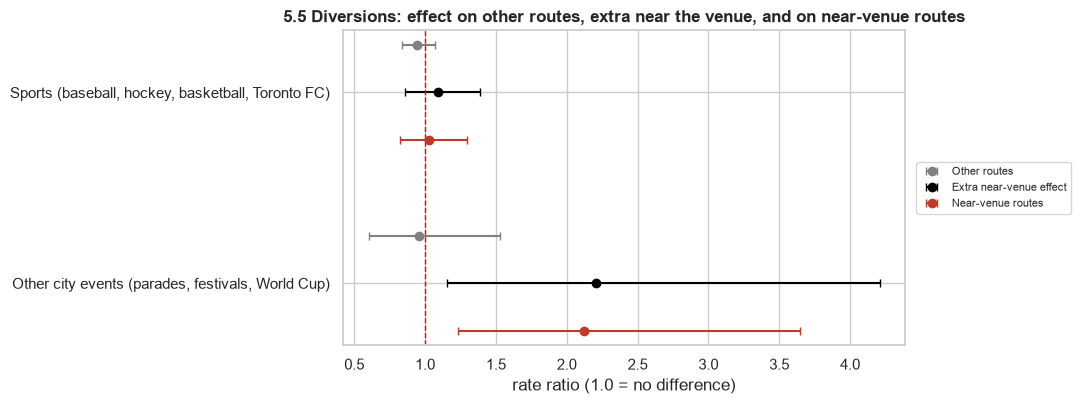

In [25]:
is_div = incidents["code"].eq("MFDV")
div_near, div_other = hourly_count(is_div & near1), hourly_count(is_div & other1)
print(f"Near-venue diversions: {int(div_near.sum())} in the period, {int(div_near[model_data['in_event_window'].to_numpy() == 1].sum())} in event hours, "
      f"{int(div_near[model_data['win_other'].to_numpy() == 1].sum())} in city-event hours | {(div_near == 0).mean():.0%} of hours have none")
near_div = stack(div_near, div_other)
res_div = fit_near(near_div, FLAGS_MAIN)
effects_div = near_effects(res_div, FLAGS_MAIN, NAMES_MAIN)
plot_effects(effects_div, "5.5 Diversions: effect on other routes, extra near the venue, and on near-venue routes")
effects_table(effects_div)

- **Diversions:** 0.88 to 1.10 for every event type, none clear. Without the five biggest diversion days and without snowy days the picture is the same (hockey 1.01 to 1.12, basketball 0.82 to 0.90, baseball 0.94 to 0.98).
- **Long delays:** 0.85 to 1.17, none clear. **Delay minutes:** 0.85 to 1.12; **basketball is clearly lower at 0.85 (0.77 to 0.93)**, everything else is within chance.
- **Near the venue:** sports 1.03 (0.82 to 1.29), city events 2.12 (1.23 to 3.65) but this rests on **13 diversions**, so the interval is wide and it should not be relied on.

## Step 6. Cause groups

The same model, with incidents of each cause group as the outcome (equipment, operator, security, miscellaneous). This answers research question 4.

In [26]:
CAUSE_LABELS = {"n_cause_Equipment": "Equipment", "n_cause_Operator": "Operator", "n_cause_Security": "Security", "n_cause_Miscellaneous": "Miscellaneous"}
cause_fits = {col: fit_poisson(model_data, col, main_rhs) for col in CAUSE_LABELS}
cause_rr = {col: rate_ratios(res).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS) for col, res in cause_fits.items()}
print({label: f"mean {model_data[col].mean():.2f} an hour" for col, label in CAUSE_LABELS.items()})

pd.DataFrame({label: [f"{r:.2f} ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(cause_rr[col]["rate_ratio"], cause_rr[col]["lo"], cause_rr[col]["hi"])]
              for col, label in CAUSE_LABELS.items()}, index=list(EVENT_FLAGS.values()))

{'Equipment': 'mean 2.56 an hour', 'Operator': 'mean 1.95 an hour', 'Security': 'mean 0.52 an hour', 'Miscellaneous': 'mean 2.94 an hour'}


,Equipment,Operator,Security,Miscellaneous
Baseball,1.03 (0.96 to 1.10),1.09 (1.01 to 1.17),0.99 (0.90 to 1.09),1.01 (0.93 to 1.09)
Hockey,1.01 (0.93 to 1.10),0.97 (0.85 to 1.10),0.93 (0.81 to 1.06),0.95 (0.83 to 1.10)
Basketball,0.99 (0.90 to 1.10),0.91 (0.81 to 1.03),0.85 (0.73 to 0.98),0.92 (0.79 to 1.06)
Toronto FC,0.98 (0.89 to 1.09),0.88 (0.76 to 1.02),1.06 (0.88 to 1.27),1.05 (0.88 to 1.24)
Other events,1.00 (0.82 to 1.22),1.00 (0.83 to 1.21),0.89 (0.61 to 1.30),0.89 (0.74 to 1.07)


- **Two cells are clear.** Basketball security incidents are lower, 0.85 (0.73 to 0.98), and baseball operator incidents are higher, 1.09 (1.01 to 1.17), a borderline rise.
- **No cause group rises clearly for any other event type.** Equipment is at 0.98 to 1.03 for all groups. Toronto FC and other events have the widest intervals.
- Parade holds (`MFPR`) are too rare to model (about 85 incidents) and `MFUS` cannot be used because its meaning changed twice.

## Step 7. Conclusions

### 7.1 One picture: every outcome and event type

,Incidents,Diversions,Long delays,Delay minutes,Equipment,Operator,Security,Miscellaneous
Baseball,1.03,0.97,0.89,1.00,1.03,1.09,0.99,1.01
Hockey,0.97,1.10,1.00,0.98,1.01,0.97,0.93,0.95
Basketball,0.93,0.88,0.85,0.85,0.99,0.91,0.85,0.92
Toronto FC,0.99,0.97,0.92,0.99,0.98,0.88,1.06,1.05
Other events,0.94,1.06,1.17,1.12,1.00,1.00,0.89,0.89


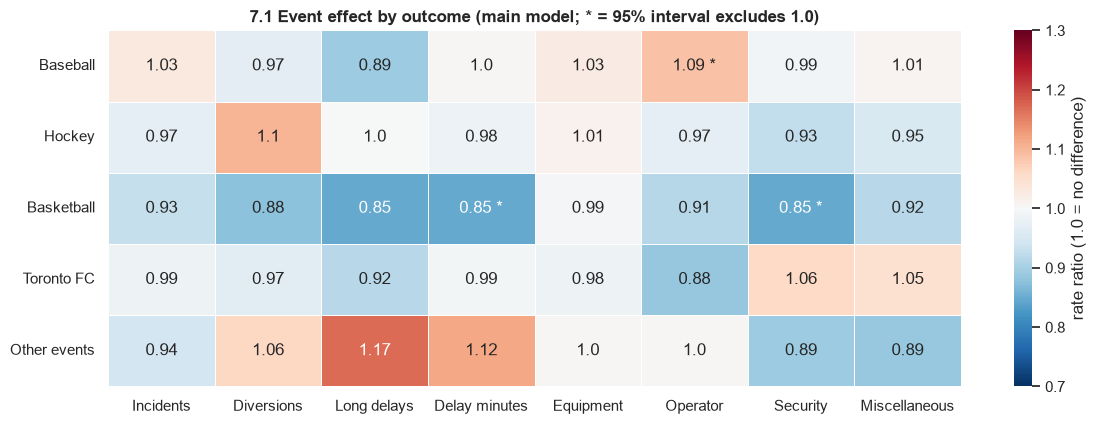

In [27]:
all_models = {"Incidents": main, **{OUTCOME_LABELS[c].split(" per")[0].split(" (")[0]: r for c, r in fits.items()}, **{label: cause_fits[col] for col, label in CAUSE_LABELS.items()}}
columns = ["Incidents", "Diversions", "Long delays", "Delay minutes", "Equipment", "Operator", "Security", "Miscellaneous"]
ratio_grid = pd.DataFrame(index=list(EVENT_FLAGS.values()), columns=columns, dtype=float)
clear_grid = pd.DataFrame(False, index=ratio_grid.index, columns=columns)
for name in columns:
    t = rate_ratios(all_models[name]).loc[list(EVENT_FLAGS)].rename(index=EVENT_FLAGS)
    ratio_grid[name] = t["rate_ratio"]
    clear_grid[name] = (t["lo"] > 1) | (t["hi"] < 1)

fig, ax = plt.subplots(figsize=(12, 4.4))
labels = ratio_grid.round(2).astype(str) + np.where(clear_grid, " *", "")
sns.heatmap(ratio_grid, annot=labels, fmt="", cmap="RdBu_r", center=1, vmin=0.7, vmax=1.3, linewidths=0.5, ax=ax, cbar_kws={"label": "rate ratio (1.0 = no difference)"})
ax.set(title="7.1 Event effect by outcome (main model; * = 95% interval excludes 1.0)", xlabel="", ylabel="")
plt.tight_layout()
ratio_grid.round(2)

**Reading the picture.** Only **three cells carry a star**: basketball delay minutes (0.85), basketball security incidents (0.85) and baseball operator incidents (1.09). Nothing for diversions, long delays or equipment, for any event type. **No event type clearly makes bus service worse.**

### 7.2 The answers to the research questions

**1. On days and hours with major events, are bus delay incidents more frequent or longer than on comparable days and hours without events?**
**No.** With day of week, hour, month, weather, holiday, coding period and untimed-event days held equal, incidents are at baseball 1.03 (0.98 to 1.08), hockey 0.97 (0.89 to 1.06), Toronto FC 0.99 (0.90 to 1.07), other events 0.94 (0.84 to 1.06) and basketball 0.93 (0.86 to 1.01). Delays are not longer: long delays 0.85 to 1.17, delay minutes 0.85 to 1.12. The only clear difference is a decrease: basketball delay minutes 0.85 (0.77 to 0.93).

**2. Which event types and venues have the largest effect?**
**None has a clear increase.** Basketball (Scotiabank Arena) is the only one that looks lower: about 7% fewer incidents (not clear) and 15% less delay time (clear), about 0.5 fewer incidents an hour. Baseball at Rogers Centre (1.03) and hockey at Scotiabank Arena (0.97) are at "no difference". Toronto FC at BMO Field looked 9% higher when Saturdays and Sundays were grouped (28 groups) but is **0.99** with day-of-week × hour groups, so it is not a finding.

**3. Is the effect concentrated on routes near the venue and in the hours around the event?**
**For sports, no, with a caveat.** With the pooled definition, near-venue routes are at 1.00 (0.92 to 1.08) and flat before, during and after the game. With "near" defined per venue, baseball (1.22, 0.98 to 1.52) and Toronto FC (1.22, 0.97 to 1.54) lean up but are borderline: **leads to check, not results**.
**For parades, the World Cup and festivals there is a possible rise on near-venue routes** (1.21, and 1.30 times the effect elsewhere), but it rests on 93 hours from 12 events: 4.0% of fake runs match the extra effect, 9.5% match the near-venue effect, and a realistic interval is about 0.95 to 1.8. **Treat it as a lead, not a result.**

**4. Which causes increase?**
**No cause group increases clearly.** Diversions (`MFDV`) are at 0.88 to 1.10 for every event type and hold without the five biggest diversion days and without snow. Parade holds (`MFPR`) are too rare to analyse and `MFUS` cannot be used because its meaning changed twice. Basketball hours have fewer security incidents (0.85); the only small rise is baseball operator incidents (1.09, borderline).

### 7.3 What this does and does not say
- **What it supports:** major sports events in Toronto do not, on average, make TTC bus service worse in the hours around them, by any of the measures here. The effects found are small (up to about 15%) next to a snow day (+16%), a day above 25 C (+32%) or a public holiday (-29%).
- **Why that may be:** TTC and the City may already plan for events (extra buses, planned diversions), or event traffic may slow roads without producing logged incidents. The data cannot tell which: it records **service incidents logged by staff**, not traffic or road speed.
- **What it cannot say:** it is not causal proof, and it has no data on buses running, so it says nothing about the *cost* of event service. The city events (parades, World Cup, festivals) are few, so they stay a lead. Weather is one daily value from one station.
- **Near-venue limits:** "near" is defined per route from the GTFS feed, so a long route counts as near even where most of its incidents are far from the venue; the `Station` field is free text and is not used. The GTFS feed is dated **Nov to Dec 2026** while the incidents run from Jan 2025 to Sep 2026, so the analysis **assumes routes and stops were stable over that period**. 35 route numbers in the incident file (2.0% of incidents) are not in the feed and stay unclassified.
- **Untimed events:** CNE, TIFF and the marathon (60 days) are only controlled for as a day-level flag; their hours are not modelled as event windows.
- **Robustness:** see `04_verification` for the other checks and fake-event tests.